In [51]:
# Task --  Predict per capita income based on the year.
import pandas as pd

In [52]:
data ={
    "year":[1970,1975,1980,1985,1990,1995,2000,2005,2010,2015,2020,2025],
    "Per_Capita_Income":[500,650,800,1000,1300,1700,2200,3000,4000,5200,6500,8000]
}

In [53]:
df=pd.DataFrame(data)

In [54]:
df.to_csv("income.csv",index=False)

In [55]:
print(df)

    year  Per_Capita_Income
0   1970                500
1   1975                650
2   1980                800
3   1985               1000
4   1990               1300
5   1995               1700
6   2000               2200
7   2005               3000
8   2010               4000
9   2015               5200
10  2020               6500
11  2025               8000


In [56]:
# Exploring the Dataset
df.head()

,year,Per_Capita_Income
0,1970,500
1,1975,650
2,1980,800
3,1985,1000
4,1990,1300


In [57]:
df.shape

(12, 2)

In [58]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   year               12 non-null     int64
 1   Per_Capita_Income  12 non-null     int64
dtypes: int64(2)
memory usage: 324.0 bytes
None


In [59]:
print(df.describe())

              year  Per_Capita_Income
count    12.000000          12.000000
mean   1997.500000        2904.166667
std      18.027756        2501.132319
min    1970.000000         500.000000
25%    1983.750000         950.000000
50%    1997.500000        1950.000000
75%    2011.250000        4300.000000
max    2025.000000        8000.000000


In [60]:
# Check Missing Values
print(df.isnull().sum())

year                 0
Per_Capita_Income    0
dtype: int64


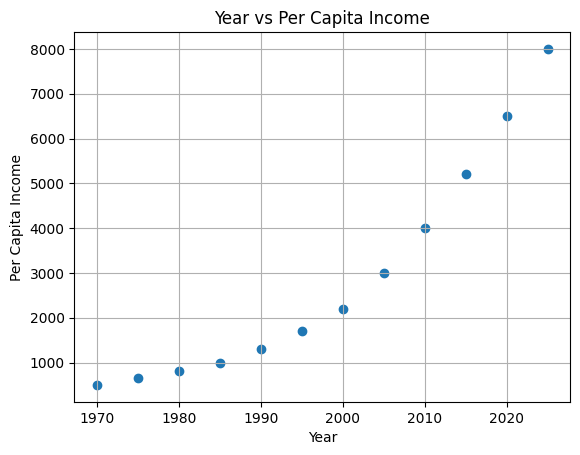

In [61]:
# Visualize the data
import matplotlib.pyplot as plt
plt.scatter(df["year"],df['Per_Capita_Income'])
plt.xlabel("Year")
plt.ylabel("Per Capita Income")
plt.title("Year vs Per Capita Income")
plt.grid()
plt.show()

In [62]:
X=df[["year"]]   # Feature
y=df["Per_Capita_Income"]  #Target

print(X.head())
print(y.head())

   year
0  1970
1  1975
2  1980
3  1985
4  1990
0     500
1     650
2     800
3    1000
4    1300
Name: Per_Capita_Income, dtype: int64


In [63]:
#Split The Data
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [64]:
X_train.shape  # Training Data

(9, 1)

In [65]:
X_test  # Testing Data

,year
10,2020
9,2015
0,1970


In [66]:
# Train the Linear Regression Model
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(X_train,y_train)

LinearRegression()

In [67]:
print("Slope",model.coef_[0])
print("Intercept",model.intercept_)

Slope 137.93296089385473
Intercept -272812.8491620111


In [68]:
y_pred=model.predict(X_test)

In [69]:
y_pred

array([ 5811.73184358,  5122.06703911, -1084.91620112])

In [70]:
results=pd.DataFrame({
    "Actaul Income": y_test.values,
    "Predicted Income":y_pred
})

In [71]:
results

,Actaul Income,Predicted Income
0,6500,5811.731844
1,5200,5122.067039
2,500,-1084.916201


In [72]:
from sklearn.metrics import(
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
rsme=np.sqrt(mse)
r2=r2_score(y_test,y_pred)

print("MAE",mae)
print("MSE",mse)
print("RMSE",rsme)
print("r2 score",r2)

MAE 783.7057728119156
MSE 997248.6553686518
RMSE 998.6233801432109
r2 score 0.8498621964148901


In [73]:
future_years=pd.DataFrame({
    "year":[2020,2030]
})

future_predictions=model.predict(future_years)

for year, income in zip(
    future_years["year"],
    future_predictions
):
    print(f"Year: {year}, Predicted Income: {income:.2f}")

Year: 2020, Predicted Income: 5811.73
Year: 2030, Predicted Income: 7191.06


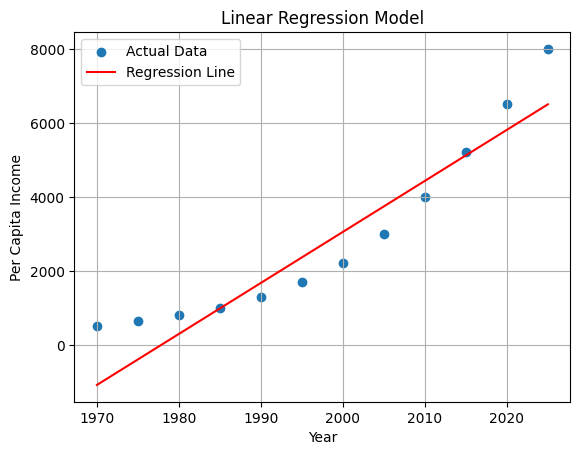

In [74]:
# Plot the regression line
plt.scatter(X["year"],y,label="Actual Data")
plt.plot(
    X["year"],
    model.predict(X),
    color="red",
    label="Regression Line"
)

plt.xlabel("Year")
plt.ylabel("Per Capita Income")
plt.title("Linear Regression Model")
plt.legend()
plt.grid(True)
plt.show()